# CDS 4003 - Stage 4: Exploratory Data Analysis and Feature Engineering
**Project:** Predicting US Accident Severity and Clearing Time (Group 7)

This notebook comes after `01_data_preparation.ipynb` and before `02_model_building.ipynb`. It holds the code behind the Stage 4 charts and numbers of the group report: the class balance, the shape of the duration, the link between severity and duration, rush hour, weather, the change over the years, and a test of how much the new features help.

It uses the function `prepare()` from `src/prep.py`, so the data is exactly the same 497,097 accidents as in the other two notebooks. The tables used for the charts are the cleaned table (`clean`) and the same table with the missing values left empty (`unfilled`). The weather shares use `unfilled`, so rows without a weather text are not counted as Clear.

In [1]:
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, KFold, train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sys.path.insert(0, '..')
from src.prep import prepare

warnings.filterwarnings('ignore')
os.makedirs('figs', exist_ok=True)
pd.set_option('display.width', 200)
SEED = 42
BLUE, GREY, RED = '#2f6db5', '#9aa5b1', '#c0392b'


def save(name):
    plt.tight_layout()
    plt.savefig(f'figs/{name}.png', dpi=160)
    plt.show()


clean, unfilled = prepare('../data/US_Accidents_March23_sampled_500k.csv')
print('rows, columns:', clean.shape)

rows, columns: (497097, 36)


## 1. Class balance of Severity
The score we use to choose the model depends on how balanced the classes are, so we check this first.

          accidents  share %
Severity                    
1              4257      0.9
2            395615     79.6
3             84452     17.0
4             12773      2.6


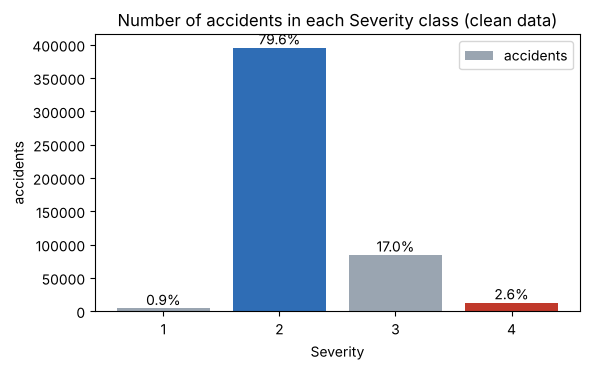

In [2]:
sev = clean['Severity'].value_counts().sort_index()
share = (sev / len(clean) * 100).round(1)
print(pd.DataFrame({'accidents': sev, 'share %': share}).to_string())

fig, ax = plt.subplots(figsize=(6, 3.8))
bars = ax.bar(sev.index.astype(str), sev.values, color=[GREY, BLUE, GREY, RED], label='accidents')
ax.set_xlabel('Severity'); ax.set_ylabel('accidents')
ax.set_title('Number of accidents in each Severity class (clean data)')
for b, s in zip(bars, share):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f'{s}%', ha='center', va='bottom')
ax.legend(loc='upper right')
save('eda_01_severity')

Severity 2 holds 79.6% of the accidents and Severity 4 only 2.6%. A model that always says Severity 2 has an accuracy of about 80% and never finds a serious accident, so accuracy alone is not a good score here. We use macro F1 and the recall of Severity 4.

## 2. Shape of Duration_Minutes

mean   : 108.1
median : 74.8
skew   : 3.5


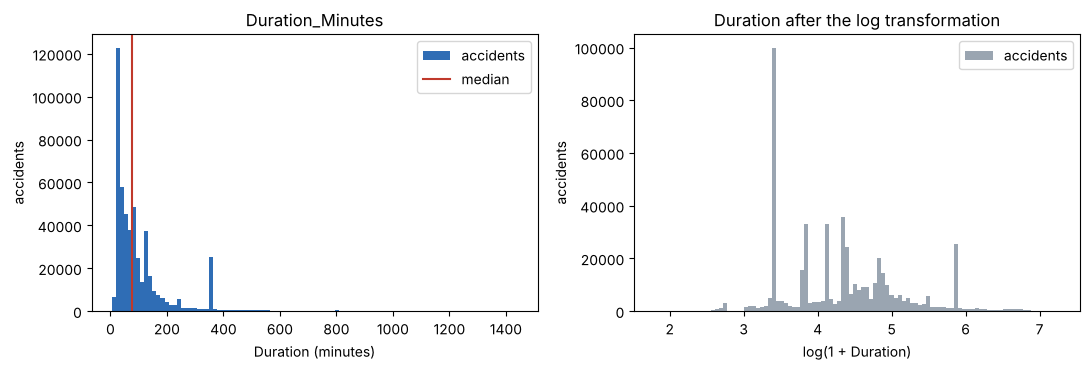

In [3]:
dur = clean['Duration_Minutes']
print('mean   :', round(dur.mean(), 1))
print('median :', round(dur.median(), 1))
print('skew   :', round(dur.skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(dur, bins=100, color=BLUE, label='accidents')
axes[0].axvline(dur.median(), color=RED, label='median')
axes[0].set_xlabel('Duration (minutes)'); axes[0].set_ylabel('accidents')
axes[0].set_title('Duration_Minutes')
axes[0].legend()
axes[1].hist(np.log1p(dur), bins=100, color=GREY, label='accidents')
axes[1].set_xlabel('log(1 + Duration)'); axes[1].set_ylabel('accidents')
axes[1].set_title('Duration after the log transformation')
axes[1].legend()
save('eda_02_duration')

The mean (108.1) is far above the median (74.8) and the skewness is 3.5, so the duration is strongly right skewed. After the log transformation the shape is much closer to a bell. For this reason the regression models predict log(1 + Duration) and the result is changed back to minutes at the end.

## 3. Severity and duration

Severity
1     44.8
2     77.4
3     44.4
4    127.5


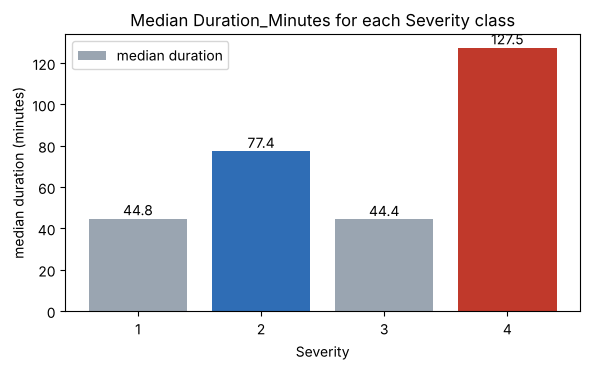

In [4]:
med_sev = clean.groupby('Severity')['Duration_Minutes'].median().round(1)
print(med_sev.to_string())

fig, ax = plt.subplots(figsize=(6, 3.8))
bars = ax.bar(med_sev.index.astype(str), med_sev.values, color=[GREY, BLUE, GREY, RED], label='median duration')
ax.set_xlabel('Severity'); ax.set_ylabel('median duration (minutes)')
ax.set_title('Median Duration_Minutes for each Severity class')
for b, v in zip(bars, med_sev.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f'{v}', ha='center', va='bottom')
ax.legend(loc='upper left')
save('eda_03_duration_by_severity')

Only Severity 4 is clearly longer (median 127.5 minutes against 77.4 for Severity 2). Severity 1 and Severity 3 have a median of only about 45 minutes. So Severity is not simply "longer accident = higher class", and we need a separate model for each target.

## 4. Time of day and rush hour

Hour
7     37876
8     37508
16    37244
17    36918
share of accidents in the six rush hours: 40.4%


                   median_duration  severity4_share
outside rush hour            76.55             2.98
rush hour                    59.85             1.96


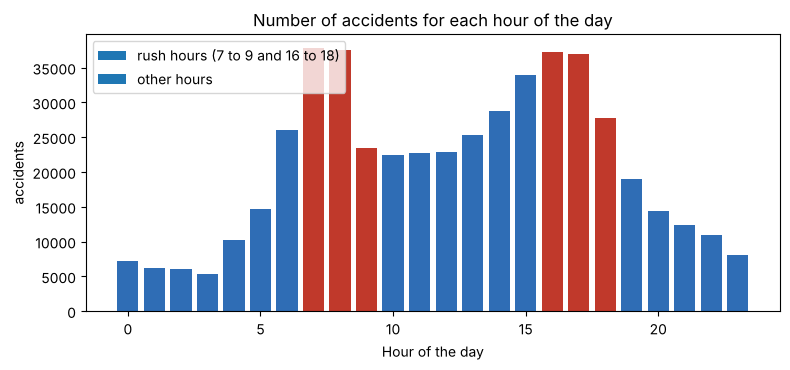

In [5]:
by_hour = clean.groupby('Hour').size()
print(by_hour.sort_values(ascending=False).head(4).to_string())
print('share of accidents in the six rush hours: %.1f%%' % (clean['Is_RushHour'].mean() * 100))

rush = clean.groupby('Is_RushHour').agg(median_duration=('Duration_Minutes', 'median'),
                                        severity4_share=('Severity', lambda s: (s == 4).mean() * 100)).round(2)
rush.index = ['outside rush hour', 'rush hour']
print(rush.to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
colors = [RED if h in (7, 8, 9, 16, 17, 18) else BLUE for h in by_hour.index]
ax.bar(by_hour.index, by_hour.values, color=colors)
ax.bar([], [], color=RED, label='rush hours (7 to 9 and 16 to 18)')
ax.bar([], [], color=BLUE, label='other hours')
ax.set_xlabel('Hour of the day'); ax.set_ylabel('accidents')
ax.set_title('Number of accidents for each hour of the day')
ax.legend()
save('eda_04_hour')

There are two peaks, in the morning and in the afternoon. The six rush hours hold 40.4% of all accidents, but these accidents are cleared faster (median 59.9 minutes against 76.6) and a smaller share is Severity 4 (2.0% against 3.0%). Busy roads have more accidents, but the accidents are lighter, so the rush hour is useful for the model but it does not mean more serious accidents.

## 5. Weather
The shares use the table with the gaps left open, so the accidents without a weather text are not counted in any group.

In [6]:
weather = unfilled.groupby('Weather_Group').agg(accidents=('Severity', 'size'),
                                                severity4_share=('Severity', lambda s: (s == 4).mean() * 100),
                                                median_duration=('Duration_Minutes', 'median')).round(2)
print(weather.sort_values('accidents', ascending=False).to_string())

num_cols = ['Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)',
            'Precipitation(in)']
corr = unfilled[num_cols + ['Severity', 'Duration_Minutes']].corr()[['Severity', 'Duration_Minutes']].loc[num_cols].round(3)
print()
print('Pearson correlation of the weather values with the two targets:')
print(corr.to_string())

                accidents  severity4_share  median_duration
Weather_Group                                              
Clear              219343             2.53            75.62
Cloudy             203436             2.53            60.95
Rain                32965             2.60            66.50
Low Visibility      13053             2.05            76.07
Snow/Ice            11368             3.33            79.35
Thunderstorm         5695             2.21            75.48
Other                 206             3.88            98.91

Pearson correlation of the weather values with the two targets:
                   Severity  Duration_Minutes
Temperature(F)       -0.019            -0.014
Humidity(%)           0.020            -0.010
Pressure(in)          0.045            -0.008
Visibility(mi)       -0.001             0.006
Wind_Speed(mph)       0.042            -0.001
Precipitation(in)     0.023            -0.003


The share of Severity 4 is 2.5% for Clear weather, 3.3% for Snow/Ice and 2.1% for Low Visibility, so snow and ice give a small increase and the other groups are close to each other. The correlations of the numeric weather values with both targets are all weak (below 0.1 in absolute value). Weather alone does not explain the severity or the duration, and this fits the low importance of the weather columns in the model.

## 6. Change over the years

      accidents  median_duration
Year                            
2016      26642             45.0
2017      46502             44.4
2018      57540             29.8
2019      61788             59.6
2020      75303             76.2
2021     100777             92.3
2022     112884             80.6
2023      15661             95.1


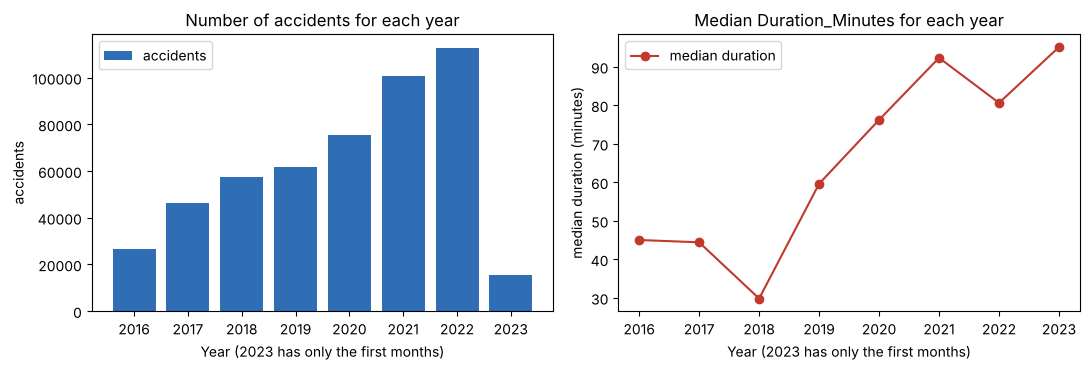

In [7]:
years = clean.groupby('Year').agg(accidents=('Severity', 'size'),
                                  median_duration=('Duration_Minutes', 'median')).round(1)
print(years.to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(years.index.astype(str), years['accidents'], color=BLUE, label='accidents')
axes[0].set_xlabel('Year (2023 has only the first months)'); axes[0].set_ylabel('accidents')
axes[0].set_title('Number of accidents for each year')
axes[0].legend(loc='upper left')
axes[1].plot(years.index.astype(str), years['median_duration'], marker='o', color=RED, label='median duration')
axes[1].set_xlabel('Year (2023 has only the first months)'); axes[1].set_ylabel('median duration (minutes)')
axes[1].set_title('Median Duration_Minutes for each year')
axes[1].legend(loc='upper left')
save('eda_05_year')

The number of accidents grows from 26,642 in 2016 to 112,884 in 2022 and the median duration grows from 45.0 to 95.1 minutes in 2023. This is probably not only a change in traffic: the way the accidents were collected also changed. We keep Year as a feature because it helps the models a lot, but Stage 6 measures how much the models depend on it.

## 7. Do the new features help?
A feature is only worth keeping if the model gets worse without it. We remove one group of new features at a time and run 3-fold cross-validation on the same 60,000-row training sample for every variant (the same folds for all variants, Random Forest with fixed settings, seed 42). The test set is not used. The score for Severity is macro F1 (higher is better) and for Duration the MAE in minutes (lower is better).

In [8]:
NUM = ['Start_Lat', 'Start_Lng', 'Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)',
       'Wind_Speed(mph)', 'POI_Count', 'Hour', 'Month', 'Year']
PRECIP = ['Precipitation(in)']
FLAGS = ['Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway', 'Station',
         'Stop', 'Traffic_Calming', 'Traffic_Signal', 'Is_Weekend', 'Is_RushHour']
CAT = ['State', 'Timezone', 'Wind_Direction', 'Sunrise_Sunset', 'Weather_Group', 'Season', 'DayOfWeek']
ALL = NUM + PRECIP + FLAGS + CAT

X = unfilled[ALL].copy()
X[FLAGS] = X[FLAGS].astype(int)
ys, yd = unfilled['Severity'], unfilled['Duration_Minutes']
X_train, X_test, ys_train, ys_test, yd_train, yd_test = train_test_split(
    X, ys, yd, test_size=0.2, stratify=ys, random_state=SEED)
X_tune, _, ys_tune, _, yd_tune, _ = train_test_split(
    X_train, ys_train, yd_train, train_size=60000, stratify=ys_train, random_state=SEED)
print('rows used for the feature test:', len(X_tune))


def make_pipe(model, features):
    num = [c for c in NUM if c in features]
    precip = [c for c in PRECIP if c in features]
    flags = [c for c in FLAGS if c in features]
    cat = [c for c in CAT if c in features]
    parts = [('num', Pipeline([('fill', SimpleImputer(strategy='mean')), ('scale', StandardScaler())]), num),
             ('precip', Pipeline([('fill', SimpleImputer(strategy='constant', fill_value=0)),
                                  ('scale', StandardScaler())]), precip),
             ('flags', 'passthrough', flags),
             ('cat', Pipeline([('fill', SimpleImputer(strategy='most_frequent')),
                               ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat)]
    parts = [p for p in parts if len(p[2]) > 0]
    return Pipeline([('prep', ColumnTransformer(parts)), ('model', model)])


variants = {
    'all features': [],
    'without POI_Count': ['POI_Count'],
    'without Weather_Group': ['Weather_Group'],
    'without Is_RushHour, Is_Weekend, Season, DayOfWeek': ['Is_RushHour', 'Is_Weekend', 'Season', 'DayOfWeek'],
    'without Hour, Month': ['Hour', 'Month'],
}
cv_c = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
cv_r = KFold(n_splits=3, shuffle=True, random_state=SEED)
rows = []
for name, removed in variants.items():
    feats = [c for c in ALL if c not in removed]
    clf = make_pipe(RandomForestClassifier(n_estimators=40, max_depth=20, max_features=0.3,
                                           class_weight='balanced', n_jobs=-1, random_state=SEED), feats)
    reg = make_pipe(RandomForestRegressor(n_estimators=40, max_depth=20, n_jobs=-1, random_state=SEED), feats)
    f1 = cross_val_score(clf, X_tune[feats], ys_tune, cv=cv_c, scoring='f1_macro').mean()
    mae = -cross_val_score(reg, X_tune[feats], np.log1p(yd_tune), cv=cv_r,
                           scoring='neg_mean_absolute_error').mean()
    rows.append({'variant': name, 'macro F1 (Severity)': round(f1, 3), 'MAE of log(1+Duration)': round(mae, 3)})
    print(rows[-1])
feature_test = pd.DataFrame(rows)
feature_test

rows used for the feature test: 60000


{'variant': 'all features', 'macro F1 (Severity)': np.float64(0.435), 'MAE of log(1+Duration)': np.float64(0.53)}


{'variant': 'without POI_Count', 'macro F1 (Severity)': np.float64(0.436), 'MAE of log(1+Duration)': np.float64(0.528)}


{'variant': 'without Weather_Group', 'macro F1 (Severity)': np.float64(0.438), 'MAE of log(1+Duration)': np.float64(0.529)}


{'variant': 'without Is_RushHour, Is_Weekend, Season, DayOfWeek', 'macro F1 (Severity)': np.float64(0.437), 'MAE of log(1+Duration)': np.float64(0.529)}


{'variant': 'without Hour, Month', 'macro F1 (Severity)': np.float64(0.419), 'MAE of log(1+Duration)': np.float64(0.545)}


,variant,macro F1 (Severity),MAE of log(1+Duration)
0,all features,0.435,0.530
1,without POI_Count,0.436,0.528
2,without Weather_Group,0.438,0.529
3,"without Is_RushHour, Is_Weekend, Season, DayOf...",0.437,0.529
4,"without Hour, Month",0.419,0.545


                                           variant  macro F1 (Severity)  MAE of log(1+Duration)  change in macro F1  change in log MAE
                                      all features                0.435                   0.530               0.000              0.000
                                 without POI_Count                0.436                   0.528               0.001             -0.002
                             without Weather_Group                0.438                   0.529               0.003             -0.001
without Is_RushHour, Is_Weekend, Season, DayOfWeek                0.437                   0.529               0.002             -0.001
                               without Hour, Month                0.419                   0.545              -0.016              0.015


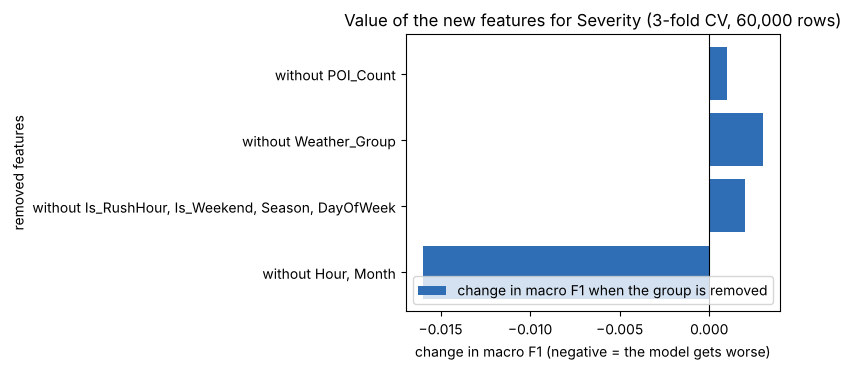

In [9]:
base = feature_test.iloc[0]
feature_test['change in macro F1'] = (feature_test['macro F1 (Severity)'] - base['macro F1 (Severity)']).round(3)
feature_test['change in log MAE'] = (feature_test['MAE of log(1+Duration)'] - base['MAE of log(1+Duration)']).round(3)
print(feature_test.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(feature_test['variant'][1:][::-1], feature_test['change in macro F1'][1:][::-1], color=BLUE,
        label='change in macro F1 when the group is removed')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('change in macro F1 (negative = the model gets worse)'); ax.set_ylabel('removed features')
ax.set_title('Value of the new features for Severity (3-fold CV, 60,000 rows)')
ax.legend(loc='lower right')
save('eda_06_feature_test')

Conclusion of this test: read the table above. A group of features that lowers the score when it is removed has value for the model. A group where the change is close to zero or positive adds no measurable value, and we keep it only because it is easy to explain to a dispatcher. The cross-validation std in the report (about 0.01 for macro F1) is the size of change that cannot be separated from noise.